# 2ACDC analysis

Plots and comparisons for 2ACDC models exported by `optimize/nested_optimize_EIANN_2ACDC.py`. Everything works from the laps saved in each pickle, so nothing here retrains.

Export a model with, from the `EIANN` package directory:

```bash
mkdir -p data/2ACDC
python -m nested.analyze --framework=serial --config-file-path=<optimize config> \
  --param-file-path=optimize/optimize_params/2ACDC/20261102_2ACDC_params.yaml --model-key=<key> \
  --output-dir=data/2ACDC --label=<key> --num_instances=5 --export --disp
```

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np

import EIANN.utils as ut
from EIANN.plot import clean_axes, update_plot_defaults
from EIANN.reinforcement_learning.environments import make_2ACDC_tracks
from EIANN.reinforcement_learning.treadmill_metrics import stack_laps, licks_by_zone
from EIANN.reinforcement_learning.treadmill_plots import SERIES_COLORS, plot_2ACDC_summary, plot_hidden_activity

%matplotlib inline
update_plot_defaults()

## Load models

In [2]:
data_dir = '../data/2ACDC'

# model name: (network config name, nested label)
models = {'van_bp': ('20261102_EIANN_2_hidden_2ACDC_van_bp_relu_SGD_config', 'van_bp_relu_SGD'),
          'eprop': ('20261102_EIANN_2_hidden_2ACDC_eprop_relu_SGD_config', 'eprop_relu_SGD')}


def load_rl_histories(network_name, label):
    """
    The rl_history of every exported seed of a model, by '<seed>_<data_seed>'.
    """
    histories = {}
    for path in sorted(glob.glob(f'{data_dir}/{network_name}/{network_name}_*_{label}.pkl')):
        seed = os.path.basename(path)[len(network_name) + 1:-len(label) - 5]
        histories[seed] = ut.load_network(path, disp=False).rl_history
    return histories


histories = {name: load_rl_histories(*model) for name, model in models.items()}
{name: list(model_histories) for name, model_histories in histories.items()}

{'van_bp': ['66049_257', '66050_258', '66051_259', '66052_260', '66053_261'],
 'eprop': ['66049_257', '66050_258', '66051_259', '66052_260', '66053_261']}

## One seed

The standard plots, the same ones as `nested.analyze --plot`.

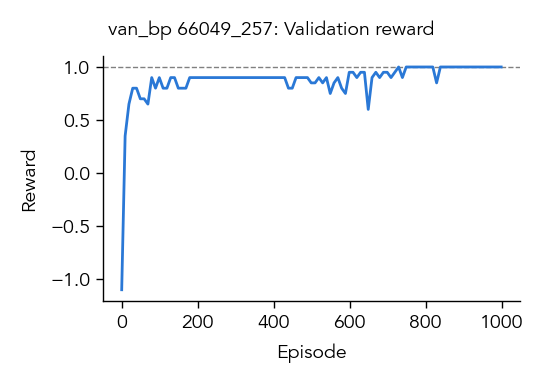

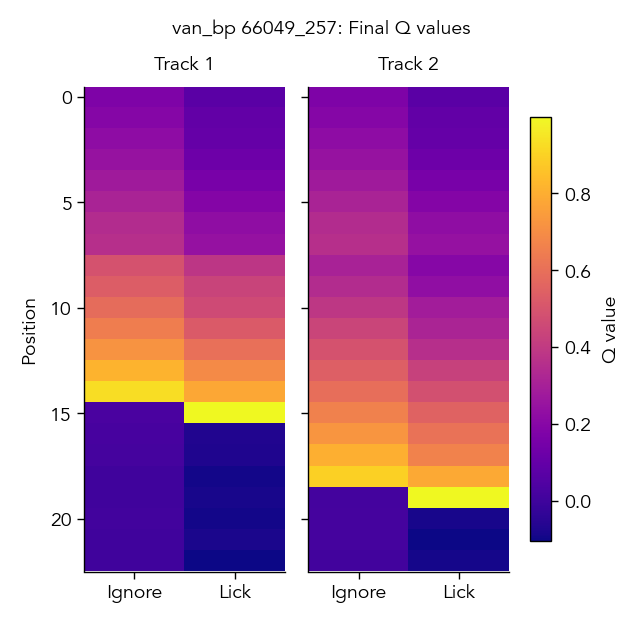

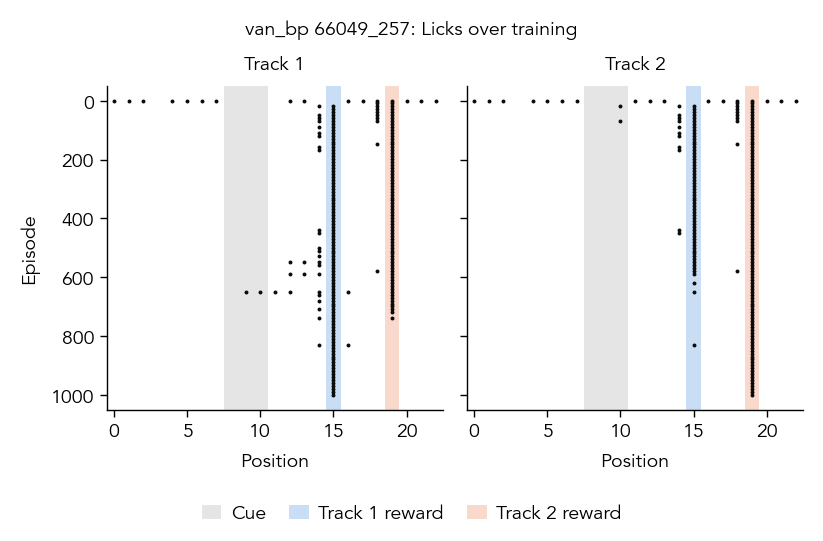

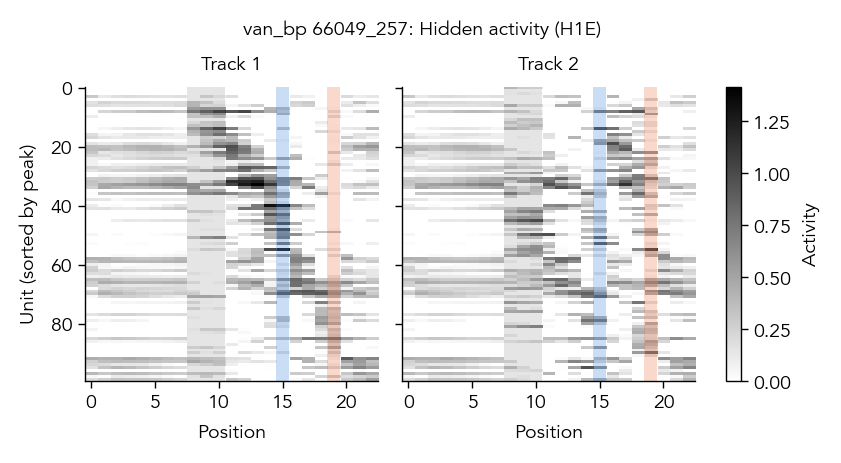

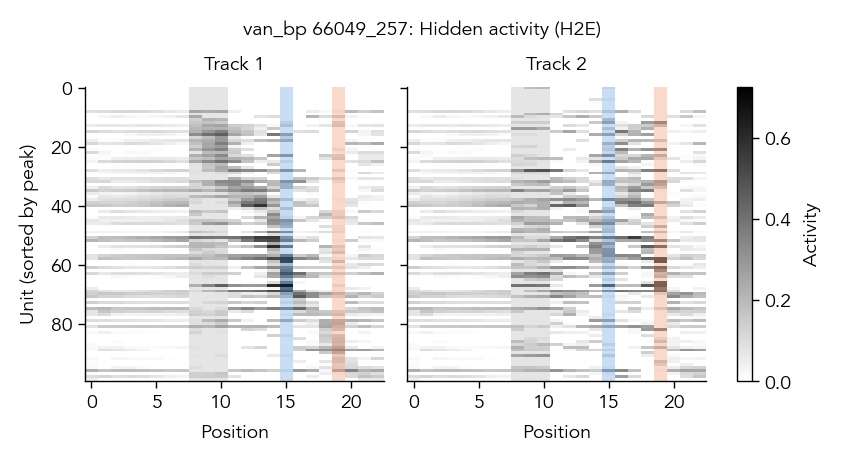

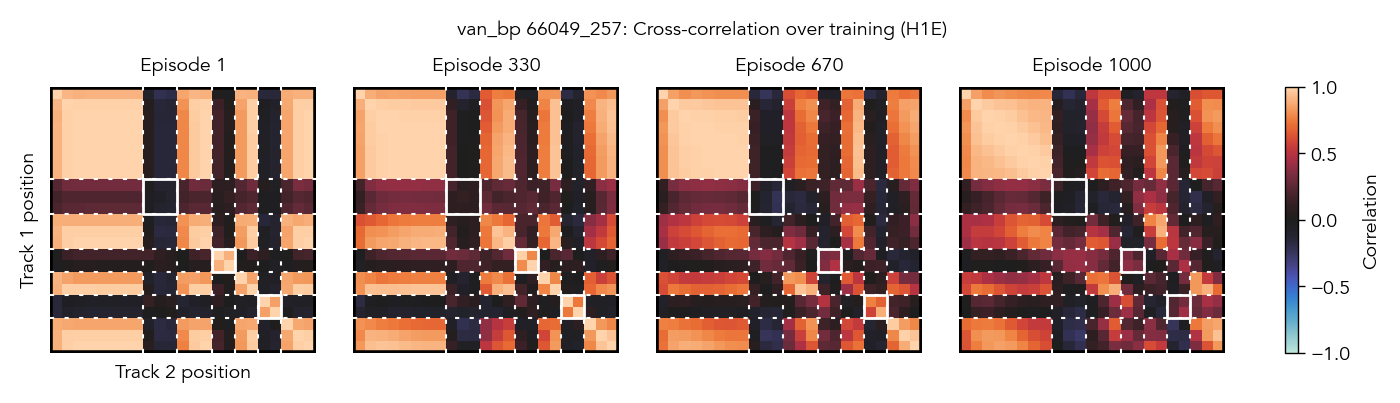

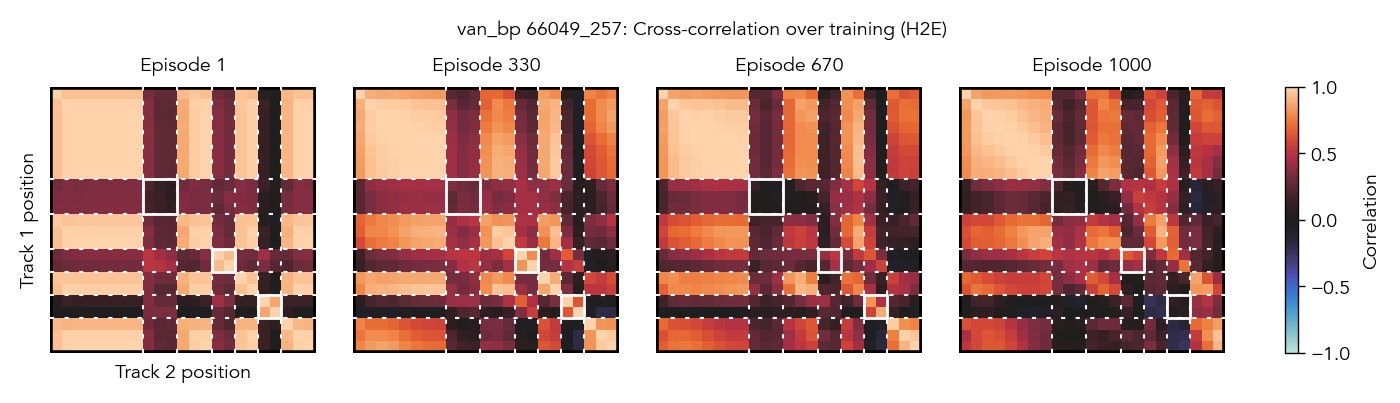

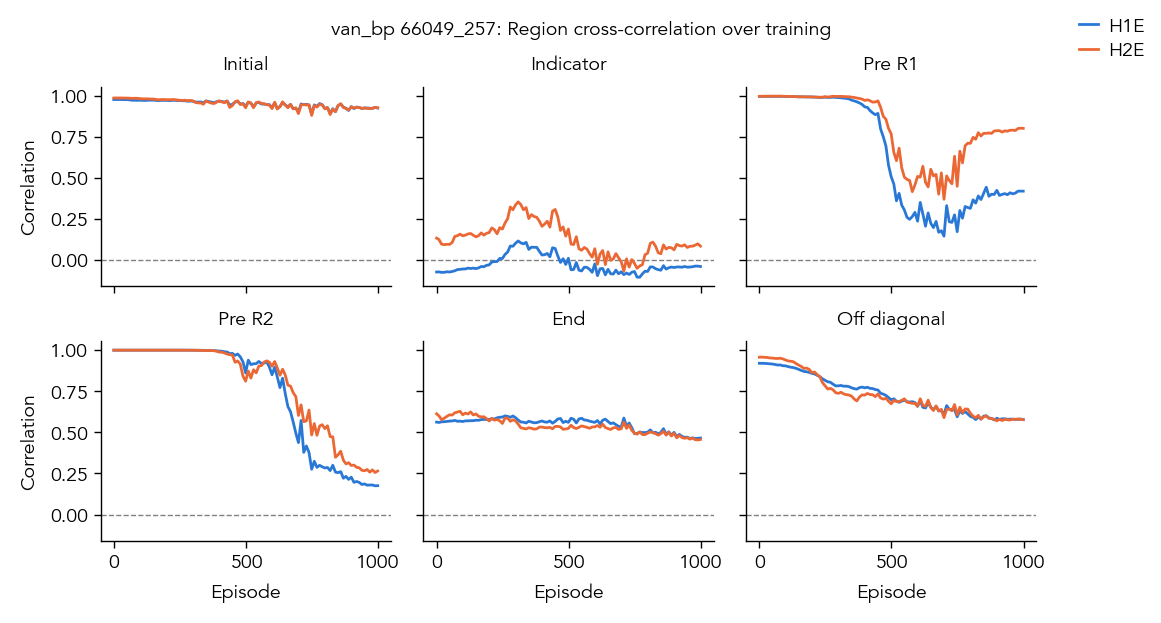

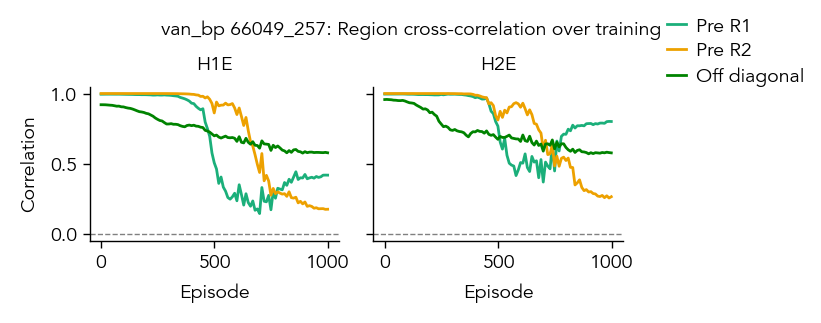

In [3]:
model, seed = 'van_bp', '66049_257'
plot_2ACDC_summary(histories[model][seed], title=f'{model} {seed}')

## Compare models

Mean ± SEM over seeds.

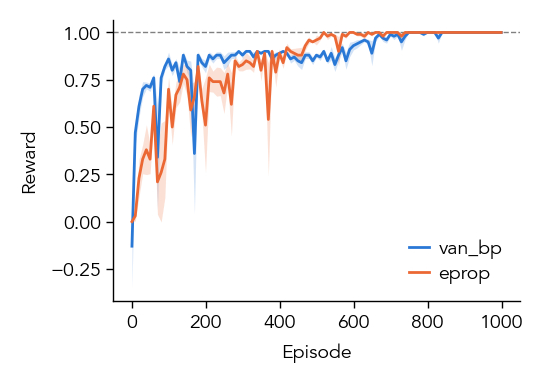

In [4]:
def get_zone_licks(history):
    """
    Mean number of licks per track in the zone that pays on that track, and in the zone that doesn't, over training.
    """
    laps = stack_laps(history['val_laps'], history['val_episodes'])
    licks = licks_by_zone(laps, make_2ACDC_tracks(**history['treadmill_kwargs'])[0])
    correct = licks.diagonal(axis1=1, axis2=2).mean(axis=1)
    wrong = licks.sum(axis=(1, 2)) / licks.shape[1] - correct
    return correct, wrong


def plot_mean_sem(ax, episodes, values, color, label=None):
    mean, sem = values.mean(axis=0), values.std(axis=0) / np.sqrt(len(values))
    ax.plot(episodes, mean, color=color, linewidth=1, label=label)
    ax.fill_between(episodes, mean - sem, mean + sem, color=color, alpha=0.2, linewidth=0)


fig, ax = plt.subplots(figsize=(2.6, 1.8), layout='constrained')
ax.axhline(1., color='gray', linestyle='--', linewidth=0.5)
for (name, model_histories), color in zip(histories.items(), SERIES_COLORS):
    rewards = np.array([history['val_rewards'] for history in model_histories.values()])
    plot_mean_sem(ax, next(iter(model_histories.values()))['val_episodes'], rewards, color, label=name)
ax.set_xlabel('Episode')
ax.set_ylabel('Reward')
ax.legend()
clean_axes(ax)
plt.show()

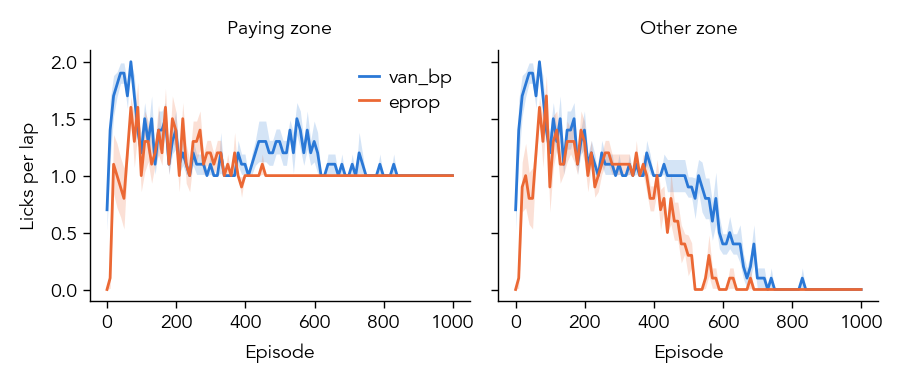

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(4.4, 1.8), sharey=True, layout='constrained')
for (name, model_histories), color in zip(histories.items(), SERIES_COLORS):
    zone_licks = np.array([get_zone_licks(history) for history in model_histories.values()])
    episodes = next(iter(model_histories.values()))['val_episodes']
    plot_mean_sem(axes[0], episodes, zone_licks[:, 0], color, label=name)
    plot_mean_sem(axes[1], episodes, zone_licks[:, 1], color)
axes[0].set_title('Paying zone')
axes[1].set_title('Other zone')
axes[0].set_ylabel('Licks per lap')
for ax in axes:
    ax.set_xlabel('Episode')
axes[0].legend()
clean_axes(axes)
plt.show()

## Individual plots

Each plot function takes `laps` and `tracks`, so any of them can be called on its own, for example hidden activity before learning.

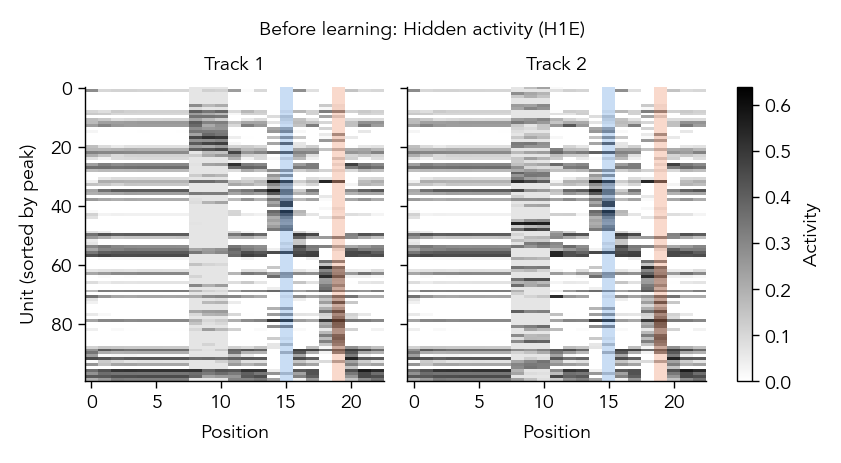

In [6]:
history = histories[model][seed]
laps = stack_laps(history['val_laps'], history['val_episodes'])
tracks = make_2ACDC_tracks(**history['treadmill_kwargs'])
plot_hidden_activity(laps, tracks, populations=['H1E'], val_step=0, title='Before learning')